#  PART A: PLAN
# 1) Problem in my own words:
#    The hotel group loses money because many guests cancel. The manager wants to build a
#    cancellation-prediction model next month. Before that he needs a clean, trustworthy dataset,
#    first answers about cancellations and prices, and a few charts. I must also explain every
#    cleaning decision and the options I rejected, because he must trust the data.
#
# 2) Logic map (Input -> Action -> Output):
#    Load      : Kaggle files            -> read_csv, keep df_original copy   -> df (119,390 x 32)
#    Inspect   : df                      -> shape/info/describe/isna/value_counts -> list of suspicious columns
#    Clean     : df + problem list       -> fill / remove / retype / keep     -> df clean + decision_log
#    Features  : clean df                -> arithmetic on columns             -> 5+ new columns
#    Analyse   : clean df                -> groupby, mean/median, crosstab    -> answers Q1-Q7
#    Visualise : clean df                -> matplotlib / seaborn              -> 5 charts
#    Save      : clean df                -> to_csv (new file)                 -> hotels_clean.csv
#
# 3) Libraries/functions planned:
#    pandas (read_csv, info, describe, isna, duplicated, groupby, crosstab, to_datetime, astype, fillna),
#    numpy (where), matplotlib + seaborn (histplot, countplot, lineplot, barplot, heatmap), kagglehub (download), pathlib (find the csv)
# 4) Changes to the plan later: (write here if you change anything and why)

In [ ]:
# PART B: LOAD
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path          # to find the csv inside the download folder (no need for os)

pd.set_option("display.max_columns", 50)

path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")
csv_path = next(Path(path).glob("*.csv"))
print("File:", csv_path)

df_original = pd.read_csv(csv_path)   # untouched copy: used only for BEFORE/AFTER comparison
df = df_original.copy()               # working copy: all cleaning happens here

print("Shape:", df.shape)
assert df.shape == (119390, 32), "Shape is different - ask the teacher!"

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
File: /kaggle/input/hotel-booking-demand/hotel_bookings.csv
Shape: (119390, 32)


In [ ]:
# PART B: INSPECT
# df.shape      -> size of the data (rows, columns)
# df.head()     -> first 5 rows: what a booking looks like
# df.info()     -> dtypes + non-null counts: shows wrong types and missing values
# df.describe() -> min/max/mean for numbers: shows impossible or strange values
# df.isna().sum() -> exact number of empty cells per column
# value_counts  -> every spelling of a category: shows inconsistent labels
print(df.shape)
display(df.head())
df.info()

display(df.describe().T)                 # numeric columns
display(df.describe(include="object").T) # text columns

missing = df.isna().sum()
print("\nColumns with missing values:")
display(missing[missing > 0])

for c in ["hotel", "meal", "market_segment", "distribution_channel", "deposit_type",
          "customer_type", "reserved_room_type", "assigned_room_type", "reservation_status"]:
    print(df[c].value_counts(dropna=False), "\n")

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613



Columns with missing values:


,0
children,4
country,488
agent,16340
company,112593


hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64 

meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64 

market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64 

distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64 

deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64 

customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64 

reserved_room_type
A    85994
D    19201
E     6535
F     2897
G     2094
B     1118
C      932
H      601
P       12
L        6
Name: count, dtype: int64 

assigned_room_type
A

In [ ]:
#  PART C: TARGET AND LEAKAGE
TARGET = "is_canceled"          # 1 = canceled, 0 = not canceled
print(df[TARGET].value_counts())
print("Cancellation rate: %.1f%%" % (df[TARGET].mean() * 100))

# LEAK 1: reservation_status
# It says Canceled / Check-Out / No-Show: this is the answer itself, known only AFTER the event.
print(pd.crosstab(df["reservation_status"], df[TARGET]))

# LEAK 2: reservation_status_date
# It is the date of the last status change: cancel date (for canceled) or check-out date .
# Compare it with the arrival date. We would not know it on the booking day.
month_map = {m: i for i, m in enumerate(["January","February","March","April","May","June","July",
             "August","September","October","November","December"], 1)}
arrival_tmp = pd.to_datetime(dict(year=df.arrival_date_year,
                                  month=df.arrival_date_month.map(month_map),
                                  day=df.arrival_date_day_of_month))
gap_days = (pd.to_datetime(df.reservation_status_date) - arrival_tmp).dt.days
print(gap_days.groupby(df[TARGET]).describe())
print(pd.crosstab(gap_days > 0, df[TARGET], rownames=["status_date AFTER arrival"], normalize="index").round(3))

#LEAK 3: assigned_room_type
# Room is assigned at check-in. Canceled guests never get a room "changed".
room_changed_tmp = df.assigned_room_type != df.reserved_room_type
print((df.groupby(room_changed_tmp)[TARGET].mean() * 100).round(1))
# booking_changes is a grey zone: changes can happen after booking. I keep it but note the risk.

#SIX FEATURES known on the booking day
def rate(key):  # cancellation % per group
    return (df.groupby(key, observed=True)[TARGET].mean() * 100).round(1)

print("1 hotel (city and resort hotels have different guests):");            print(rate(df["hotel"]))
print("2 lead_time (long wait -> more time to change plans):");
print(rate(pd.cut(df["lead_time"], [-1, 7, 30, 90, 180, 800])))
print("3 deposit_type (money at stake):");                                    print(rate(df["deposit_type"]))
print("4 previous_cancellations (past behaviour):");                          print(rate(df["previous_cancellations"] > 0))
print("5 market_segment (who books: groups, online, direct):");               print(rate(df["market_segment"]))
print("6 customer_type (contract, transient, group):");                       print(rate(df["customer_type"]))

is_canceled
0    75166
1    44224
Name: count, dtype: int64
Cancellation rate: 37.0%
is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207
               count       mean        std    min    25%   50%   75%   max
is_canceled                                                               
0            75166.0   3.390376   2.576150    0.0    2.0   3.0   4.0  69.0
1            44224.0 -85.880630  90.694686 -526.0 -127.0 -54.0 -17.0   0.0
is_canceled                    0      1
status_date AFTER arrival              
False                      0.016  0.984
True                       1.000  0.000
False    41.6
True      5.4
Name: is_canceled, dtype: float64
1 hotel (city and resort hotels have different guests):
hotel
City Hotel      41.7
Resort Hotel    27.8
Name: is_canceled, dtype: float64
2 lead_time (long wait -> more time to change plans):
lead_time
(-1, 7]        9.6
(7, 30]

In [ ]:
# PART D: FIND PROBLEMS
problems = []
def add(column, problem, rows, code, real_or_mistake):
    problems.append({"column": column, "problem": problem, "rows": int(rows),
                     "code": code, "mistake_or_real?": real_or_mistake})

guests = df.adults + df.children.fillna(0) + df.babies
nights = df.stays_in_weekend_nights + df.stays_in_week_nights
iqr_q1, iqr_q3 = df.adr.quantile([.25, .75]); iqr_hi = iqr_q3 + 1.5 * (iqr_q3 - iqr_q1)

add("country",  "Missing values", df.country.isna().sum(), "df.country.isna().sum()", "Missing data, guest nationality was not recorded")
add("children", "Missing values (4 rows only)", df.children.isna().sum(), "df.children.isna().sum()", "Mistake/blank, almost surely no children")
add("agent",    "Missing that is NOT missing (no agent)", df.agent.isna().sum(), "df.agent.isna().sum()", "Real: paper says NaN = booking not made by an agent")
add("company",  "Missing that is NOT missing (no company)", df.company.isna().sum(), "df.company.isna().sum()", "Real: NaN = no company paid")
add("all columns", "Exact repeated rows", df.duplicated().sum(), "df.duplicated().sum()", "Partly real: no booking ID, two similar guests can look identical")
add("adults/children/babies", "0 guests in a booking", (guests == 0).sum(), "((adults+children+babies)==0).sum()", "Mistake: a booking needs a guest")
add("stays_*_nights", "0 nights in total", (nights == 0).sum(), "(weekend+week nights == 0).sum()", "Mostly impossible for a booking with a stay; maybe day-use")
add("adults", "Strange: 10 or more adults", (df.adults >= 10).sum(), "(df.adults>=10).sum()", "Possible group, but isolated values like 55 look like entry errors")
add("babies", "Strange: 9-10 babies", (df.babies >= 9).sum(), "(df.babies>=9).sum()", "Mistake, impossible in a room")
add("lead_time", "Strange: booked more than 500 days ahead", (df.lead_time > 500).sum(), "(df.lead_time>500).sum()", "Possible (weddings, groups)")
add("days_in_waiting_list", "Strange: waiting over 300 days", (df.days_in_waiting_list > 300).sum(), "(df.days_in_waiting_list>300).sum()", "Possible but rare")
add("adr", "Negative price", (df.adr < 0).sum(), "(df.adr<0).sum()", "Mistake (or refund coded wrongly)")
add("adr", "Price = 0", (df.adr == 0).sum(), "(df.adr==0).sum()", "Could be real: free/complementary stays")
add("adr", "Extreme price > 1000", (df.adr > 1000).sum(), "(df.adr>1000).sum()", "Mistake, far above everything else")
add("adr", "IQR rule flags high prices", (df.adr > iqr_hi).sum(), "adr > Q3+1.5*IQR", "Need to check WHEN/WHERE (see Part E)")
add("meal", "Two labels for the same thing: 'Undefined' and 'SC' (no meal package)", df.meal.isin(["Undefined", "SC"]).sum(), "df.meal.value_counts()", "Inconsistent label (paper says same meaning)")
add("market_segment / distribution_channel", "Label 'Undefined'", ((df.market_segment == "Undefined") | (df.distribution_channel == "Undefined")).sum(), "value_counts()", "Missing information hidden as text")
add("country", "Non 3-letter ISO codes (e.g. 'CN' beside 'CHN')", df.country.dropna().str.len().ne(3).sum(), "country.str.len().ne(3).sum()", "Inconsistent label")
add("children / agent / company", "Stored as float (they are whole numbers/IDs)", len(df), "df.dtypes", "Wrong data type")
add("arrival_date_month", "Month is text, date is split over 3 columns", len(df), "df[['arrival_date_year','arrival_date_month','arrival_date_day_of_month']].dtypes", "Badly stored date")

problems_df = pd.DataFrame(problems)
display(problems_df)
print("Number of problems found:", len(problems_df))

print(df.country.value_counts().loc[lambda s: s.index.str.len() != 3])
print(df.nlargest(5, "adr")[["hotel", "arrival_date_month", "adr"]])
print(df.meal.value_counts())

,column,problem,rows,code,mistake_or_real?
0,country,Missing values,488,df.country.isna().sum(),"Missing data, guest nationality was not recorded"
1,children,Missing values (4 rows only),4,df.children.isna().sum(),"Mistake/blank, almost surely no children"
2,agent,Missing that is NOT missing (no agent),16340,df.agent.isna().sum(),Real: paper says NaN = booking not made by an ...
3,company,Missing that is NOT missing (no company),112593,df.company.isna().sum(),Real: NaN = no company paid
4,all columns,Exact repeated rows,31994,df.duplicated().sum(),"Partly real: no booking ID, two similar guests..."
5,adults/children/babies,0 guests in a booking,180,((adults+children+babies)==0).sum(),Mistake: a booking needs a guest
6,stays_*_nights,0 nights in total,715,(weekend+week nights == 0).sum(),Mostly impossible for a booking with a stay; m...
7,adults,Strange: 10 or more adults,13,(df.adults>=10).sum(),"Possible group, but isolated values like 55 lo..."
8,babies,Strange: 9-10 babies,2,(df.babies>=9).sum(),"Mistake, impossible in a room"
9,lead_time,Strange: booked more than 500 days ahead,481,(df.lead_time>500).sum(),"Possible (weddings, groups)"


Number of problems found: 20
country
CN    1279
Name: count, dtype: int64
               hotel arrival_date_month     adr
48515     City Hotel              March  5400.0
111403    City Hotel                May   510.0
15083   Resort Hotel               July   508.0
103912    City Hotel           December   451.5
13142   Resort Hotel             August   450.0
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64


In [ ]:
#PART E: CLEAN
df = df_original.copy()
decision_log = []
def log(problem, decision, tool, why, rejected, before, after):
    decision_log.append({"problem": problem, "decision": decision, "tool": tool, "why": why,
                         "rejected option": rejected, "rows before": before, "rows after": after})

# E1- Repeated rows
dup_mask = df.duplicated()
rate_with    = df[TARGET].mean() * 100
rate_without = df.loc[~dup_mask, TARGET].mean() * 100
rate_dups    = df.loc[dup_mask, TARGET].mean() * 100
print("Duplicate rows:", dup_mask.sum())
print("Cancel rate WITH duplicates   : %.1f%%" % rate_with)
print("Cancel rate WITHOUT duplicates: %.1f%%" % rate_without)
print("Cancel rate INSIDE the duplicates only: %.1f%%" % rate_dups)
# DECISION: drop duplicates, keep first.
# WHY: there is no booking ID, but 32 columns match exactly (dates, price, agent, country...). The
#      duplicates have a different cancel rate than the rest, so they bias the model-training data.
#      I would give the manager the version WITHOUT duplicates and tell him the rate with them.
# REJECTED: keep all (inflates cancel rate; model may memorise copies), or keep only duplicates inside
#      the same day (cannot do, no booking time column).
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log("exact repeated rows", "Remove (keep first)", "drop_duplicates()",
    f"cancel rate {rate_with:.1f}% -> {rate_without:.1f}%", "Keep all: copies bias the rate", before, len(df))

#E2- Missing values
# country: 'Unknown' (feature, not target; filling with 'PRT' would invent information; dropping loses bookings)
n = df.country.isna().sum(); before = len(df)
df["country"] = df["country"].fillna("Unknown")
df["country"] = df["country"].replace({"CN": "CHN"})   # same country, two codes
log(f"country missing in {n} rows + CN/CHN", "Fill 'Unknown'; CN -> CHN", "fillna, replace",
    "Honest label; CN and CHN are the same country", "Fill most common (PRT): invents data", before, len(df))

# children: 4 rows only; NaN almost surely means 0 children (adults present)
n = df.children.isna().sum(); before = len(df)
df["children"] = df["children"].fillna(0)
log(f"children missing in {n} rows", "Fill 0", "fillna(0)", "Tiny number; 0 is the typical value",
    "Drop rows: loses real bookings for no reason", before, len(df))

# agent/company: NaN means 'no agent' / 'no company' (paper). It's information, so 0 = none.
n_a, n_c = df.agent.isna().sum(), df.company.isna().sum(); before = len(df)
df["agent"] = df["agent"].fillna(0)
df["company"] = df["company"].fillna(0)
log(f"agent NaN {n_a}, company NaN {n_c}", "Fill 0 = 'none' (keep columns)", "fillna(0)",
    "NaN is a real meaning (not made through agent/company)", "Drop columns: loses whether an agent was used", before, len(df))

# E3-Inconsistent labels
before = len(df)
print("meal before:", df.meal.value_counts().to_dict())
df["meal"] = df["meal"].replace({"Undefined": "SC"})              # same meaning per paper
for c in ["market_segment", "distribution_channel"]:
    df[c] = df[c].replace({"Undefined": "Unknown"})
print("meal after:", df.meal.value_counts().to_dict())
log("meal Undefined vs SC; Undefined segment/channel", "Merge to SC; rename to Unknown", "replace",
    "Paper: Undefined and SC both mean no meal package", "Drop rows: loses bookings, tiny gain", before, len(df))

#E4-Data types
before = len(df)
for c in ["children", "agent", "company"]:
    df[c] = df[c].astype(int)
log("children/agent/company are float", "Convert to int", "astype(int)",
    "People and IDs are whole numbers; only possible after filling NaN", "Keep float: 2.0 children looks wrong", before, len(df))
print(df[["children", "agent", "company"]].dtypes)

Duplicate rows: 31994
Cancel rate WITH duplicates   : 37.0%
Cancel rate WITHOUT duplicates: 27.5%
Cancel rate INSIDE the duplicates only: 63.1%
meal before: {'BB': 67978, 'SC': 9481, 'HB': 9085, 'Undefined': 492, 'FB': 360}
meal after: {'BB': 67978, 'SC': 9973, 'HB': 9085, 'FB': 360}
children    int64
agent       int64
company     int64
dtype: object


In [ ]:
#E5-Impossible
before = len(df)
guests = df.adults + df.children + df.babies
nights = df.stays_in_weekend_nights + df.stays_in_week_nights
print("0 guests:", (guests == 0).sum(), "| 0 nights:", (nights == 0).sum(),
      "| adults>=10:", (df.adults >= 10).sum(), "| babies>=9:", (df.babies >= 9).sum())
bad = (guests == 0) | (nights == 0) | (df.adults >= 10) | (df.babies >= 9)
print("Rows removed in this step:", bad.sum(), "| their cancel rate: %.1f%%" % (df.loc[bad, TARGET].mean() * 100))
# DECISION: remove. WHY: a stay with nobody or 0 nights cannot happen, total price/nights would be 0,
#          and 9 babies in one room is a typing error. Few rows, so removal costs almost nothing.
# REJECTED: fill guests with 1 (invents data); keep 0-night rows (zero price & stay features).
df = df[~bad].reset_index(drop=True)
log("0 guests, 0 nights, >=10 adults, >=9 babies", "Remove", "boolean mask",
    "Impossible in a real hotel", "Fix by guessing values: invented data", before, len(df))

# lead_time up to ~700 days and days_in_waiting_list: KEEP (possible, real behaviour of weddings/groups)
log("lead_time > 500, long waiting list", "Keep", "-", "Possible and meaningful for cancellation", "Remove: would delete real far-ahead bookings", len(df), len(df))

#E6-Price: IQR evidence
q1, q3 = df.adr.quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = df[(df.adr < lo) | (df.adr > hi)]
print(f"IQR bounds: {lo:.1f} to {hi:.1f}; rows flagged: {len(out)} ({len(out)/len(df)*100:.1f}%)")
print(out.groupby("hotel").size())
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
print(out.arrival_date_month.value_counts().reindex(month_order))
print(out.adr.describe())
print("Negative prices:", (df.adr < 0).sum(), "| adr > 1000:", (df.adr > 1000).sum(), "| adr == 0:", (df.adr == 0).sum())
display(pd.crosstab(df.adr == 0, df.market_segment))
# DECISION: keep IQR outliers (they come mostly from the summer months/ Resort Hotel = real seasonal prices),
#          remove only adr < 0 and adr > 1000 (single values far beyond any room price: mistakes).
#          Keep adr == 0 (complementary/free stays exist, see market_segment table).
# REJECTED: delete all IQR outliers: would remove real high-season prices, and our model would never see summer.
before = len(df)
df = df[(df.adr >= 0) & (df.adr <= 1000)].reset_index(drop=True)
log("adr IQR outliers / negative / >1000", "Keep IQR outliers; remove adr<0 and adr>1000", "boolean mask",
    "IQR flags are seasonal; only 1-2 values are real mistakes", "Remove all IQR outliers: deletes real summer prices", before, len(df))
log("adr == 0", "Keep", "-", "Complementary / free stays are real", "Remove: loses real stays", len(df), len(df))

0 guests: 166 | 0 nights: 651 | adults>=10: 13 | babies>=9: 2
Rows removed in this step: 772 | their cancel rate: 6.7%
IQR bounds: -19.4 to 226.8; rows flagged: 2509 (2.9%)
hotel
City Hotel       784
Resort Hotel    1725
dtype: int64
arrival_date_month
January         3
February       12
March          25
April          74
May           119
June          153
July          574
August       1394
September      73
October        28
November        6
December       48
Name: count, dtype: int64
count    2509.000000
mean      261.580108
std       107.552002
min       226.840000
25%       236.000000
50%       250.000000
75%       271.670000
max      5400.000000
Name: adr, dtype: float64
Negative prices: 1 | adr > 1000: 1 | adr == 0: 1039


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Unknown
adr,,,,,,,,
False,222,62,4135,11572,4721,13627,51244,2
True,0,620,19,72,171,117,40,0


In [ ]:
#E7- Arrival date
before = len(df)
df["arrival_date"] = pd.to_datetime(dict(year=df.arrival_date_year,
                                         month=df.arrival_date_month.map(month_map),
                                         day=df.arrival_date_day_of_month))
df = df.drop(columns=["arrival_date_year", "arrival_date_month", "arrival_date_day_of_month"])
# arrival_date_week_number is kept (still useful).
log("date split over 3 columns, month as text", "Build one datetime column arrival_date", "to_datetime + map",
    "One real date allows weekday/month/seasons", "Keep 3 columns: cannot sort or compute weekday", before, len(df))
print(df["arrival_date"].dtype, df["arrival_date"].min(), df["arrival_date"].max())

datetime64[ns] 2015-07-01 00:00:00 2017-08-31 00:00:00


In [ ]:
# PART F: NEW FEATURES
df["total_nights"]  = df.stays_in_weekend_nights + df.stays_in_week_nights   # length of stay
df["total_guests"]  = df.adults + df.children + df.babies                    # party size
df["total_price"]   = (df.adr * df.total_nights).round(2)                    # total money for the stay (adr is per night)
df["arrival_weekday"] = df.arrival_date.dt.day_name()                        # day of week of arrival
df["has_children"]  = ((df.children + df.babies) > 0).astype(int)            # family booking?
df["room_changed"]  = (df.assigned_room_type != df.reserved_room_type).astype(int)   # LEAKAGE test

# WHY each may help: longer stays / more guests / higher total price = more money & effort at risk;
# weekday = business vs leisure trips; has_children = families rarely cancel (check below).
for c in ["total_nights", "total_guests", "total_price", "has_children", "room_changed"]:
    print(c); print(df.groupby(TARGET)[c].mean().round(2), "\n")
print("Cancel rate by arrival weekday (%):")
print((df.groupby("arrival_weekday")[TARGET].mean() * 100).round(1).sort_values())

# room_changed is LEAKAGE: assigned only at check-in, canceled guests never get a room. Same for
# reservation_status/_date. I REMOVE all of them from the clean file so nobody trains on them by mistake.
df = df.drop(columns=["reservation_status", "reservation_status_date", "assigned_room_type", "room_changed"])
print(df.shape)

total_nights
is_canceled
0    3.52
1    4.01
Name: total_nights, dtype: float64 

total_guests
is_canceled
0    1.98
1    2.14
Name: total_guests, dtype: float64 

total_price
is_canceled
0    366.59
1    478.84
Name: total_price, dtype: float64 

has_children
is_canceled
0    0.09
1    0.13
Name: has_children, dtype: float64 

room_changed
is_canceled
0    0.19
1    0.03
Name: room_changed, dtype: float64 

Cancel rate by arrival weekday (%):
arrival_weekday
Tuesday      24.6
Wednesday    25.8
Sunday       26.7
Monday       26.9
Thursday     27.9
Saturday     30.2
Friday       30.7
Name: is_canceled, dtype: float64
(86622, 32)


In [ ]:
#FINAL CHECKS + SAVE
print("Missing values total:", df.isna().sum().sum())
print("Impossible bookings:", ((df.adults + df.children + df.babies) == 0).sum(),
      "| zero nights:", (df.total_nights == 0).sum(), "| adr<0:", (df.adr < 0).sum())
print("Duplicates left:", df.duplicated().sum())
print(df.dtypes)
print("arrival_date dtype:", df.arrival_date.dtype)

# original file unchanged? (compare df_original with a fresh read)
print("Original unchanged:", df_original.equals(pd.read_csv(csv_path)), df_original.shape)

df.to_csv("hotels_clean.csv", index=False)         # NEW file, original is not touched
print("Saved. Rows: %d (was %d, removed %d)" % (len(df), len(df_original), len(df_original) - len(df)))

display(pd.DataFrame(decision_log))                # this table = the decision table of the documentation

# from google.colab import files; files.download("hotels_clean.csv")   # un-comment to download

Missing values total: 0
Impossible bookings: 0 | zero nights: 0 | adr<0: 0
Duplicates left: 1244
hotel                                     object
is_canceled                                int64
lead_time                                  int64
arrival_date_week_number                   int64
stays_in_weekend_nights                    int64
stays_in_week_nights                       int64
adults                                     int64
children                                   int64
babies                                     int64
meal                                      object
country                                   object
market_segment                            object
distribution_channel                      object
is_repeated_guest                          int64
previous_cancellations                     int64
previous_bookings_not_canceled             int64
reserved_room_type                        object
booking_changes                            int64
deposit_type         

,problem,decision,tool,why,rejected option,rows before,rows after
0,exact repeated rows,Remove (keep first),drop_duplicates(),cancel rate 37.0% -> 27.5%,Keep all: copies bias the rate,119390,87396
1,country missing in 452 rows + CN/CHN,Fill 'Unknown'; CN -> CHN,"fillna, replace",Honest label; CN and CHN are the same country,Fill most common (PRT): invents data,87396,87396
2,children missing in 4 rows,Fill 0,fillna(0),Tiny number; 0 is the typical value,Drop rows: loses real bookings for no reason,87396,87396
3,"agent NaN 12193, company NaN 82137",Fill 0 = 'none' (keep columns),fillna(0),NaN is a real meaning (not made through agent/...,Drop columns: loses whether an agent was used,87396,87396
4,meal Undefined vs SC; Undefined segment/channel,Merge to SC; rename to Unknown,replace,Paper: Undefined and SC both mean no meal package,"Drop rows: loses bookings, tiny gain",87396,87396
5,children/agent/company are float,Convert to int,astype(int),People and IDs are whole numbers; only possibl...,Keep float: 2.0 children looks wrong,87396,87396
6,"0 guests, 0 nights, >=10 adults, >=9 babies",Remove,boolean mask,Impossible in a real hotel,Fix by guessing values: invented data,87396,86624
7,"lead_time > 500, long waiting list",Keep,-,Possible and meaningful for cancellation,Remove: would delete real far-ahead bookings,86624,86624
8,adr IQR outliers / negative / >1000,Keep IQR outliers; remove adr<0 and adr>1000,boolean mask,IQR flags are seasonal; only 1-2 values are re...,Remove all IQR outliers: deletes real summer p...,86624,86622
9,adr == 0,Keep,-,Complementary / free stays are real,Remove: loses real stays,86622,86622


In [ ]:
#PART G: MANAGERS QUESTIONS
month_name = df.arrival_date.dt.month_name()

# Q1: % canceled per hotel
q1 = (df.groupby("hotel")[TARGET].mean() * 100).round(1); print("Q1\n", q1)
# Sentence: write what you see, e.g. "City Hotel loses X% of bookings, more than Resort Hotel".

# Q2: market segment with most / fewest cancellations
q2 = (df.groupby("market_segment")[TARGET].mean() * 100).round(1).sort_values(ascending=False)
print("Q2\n", q2, "\nMost:", q2.index[0], q2.iloc[0], "| Least:", q2.index[-1], q2.iloc[-1])
print(df.market_segment.value_counts())   # check small segments before trusting 0% or 100%

# Q3: lead time, mean vs median
print("Q3\n", df.groupby(TARGET)["lead_time"].agg(["mean", "median"]).round(1))
# Mean is much higher than median because a few very long lead times (up to ~700 days) pull the mean up
# (right-skewed). Median is the "typical" booking.

# Q4: most expensive month per hotel (mean adr)
q4 = df.groupby(["hotel", month_name])["adr"].mean().unstack(0).round(1)
print("Q4\n", q4.reindex(["January","February","March","April","May","June","July","August","September","October","November","December"]))
print("Most expensive month:", q4.idxmax().to_dict())

# Q5: Non Refund
nr = df[df.deposit_type == "Non Refund"]
print("Q5 Non Refund bookings:", len(nr), "| canceled: %.1f%%" % (nr[TARGET].mean() * 100))
print((df.groupby("deposit_type")[TARGET].mean() * 100).round(1))
print(pd.crosstab(nr.market_segment, nr[TARGET]))
# Strange: guests who paid in advance with no refund should cancel LEAST, but they cancel most.
# Questions for the manager: How is deposit_type recorded - at booking or after cancellation?
# Does "canceled" include no-shows that forfeited the deposit? Are group/agent bookings in Portugal coded Non Refund by default?

# Q6 (cancellations): Do guests with a previous cancellation cancel more?
q6 = (df.groupby(df.previous_cancellations > 0)[TARGET].mean() * 100).round(1)
print("Q6 cancel % (False = no previous cancellation, True = had one)\n", q6)

# Q7 (prices): Do bookings with children pay a higher price per night?
q7 = df.groupby("has_children")["adr"].mean().round(1)
print("Q7 mean adr (euro per night): 0 = no children, 1 = children\n", q7)

Q1
 hotel
City Hotel      30.2
Resort Hotel    23.7
Name: is_canceled, dtype: float64
Q2
 market_segment
Unknown          100.0
Online TA         35.5
Groups            27.2
Aviation          19.8
Offline TA/TO     14.9
Direct            14.8
Corporate         12.2
Complementary     12.2
Name: is_canceled, dtype: float64 
Most: Unknown 100.0 | Least: Complementary 12.2
market_segment
Online TA        51284
Offline TA/TO    13743
Direct           11644
Groups            4891
Corporate         4154
Complementary      682
Aviation           222
Unknown              2
Name: count, dtype: int64
Q3
               mean  median
is_canceled               
0             70.5    38.0
1            105.7    80.0
Q4
 hotel         City Hotel  Resort Hotel
arrival_date                          
January             85.8          49.9
February            90.1          54.6
March               94.5          58.2
April              117.5          79.8
May                128.4          81.5
June          

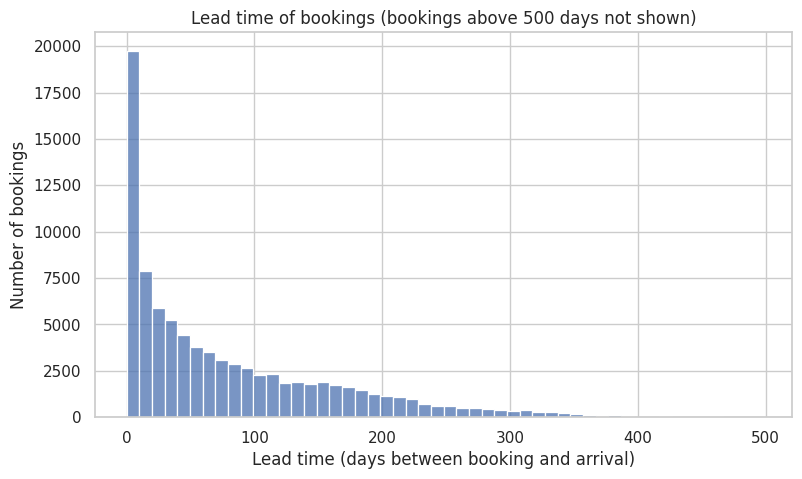

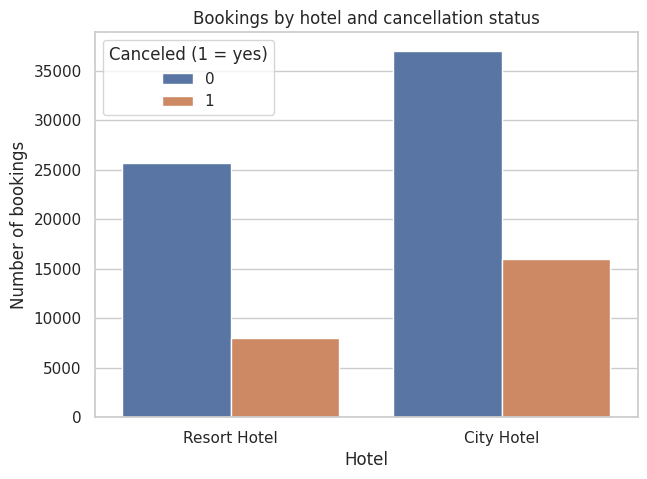

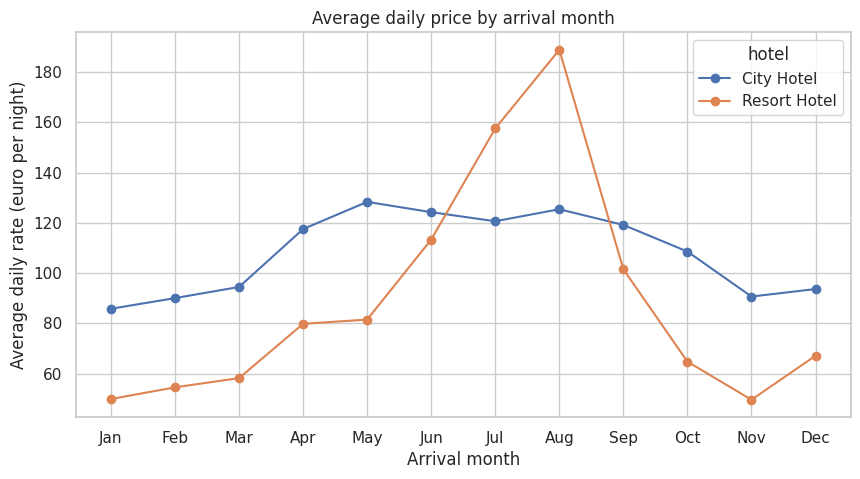

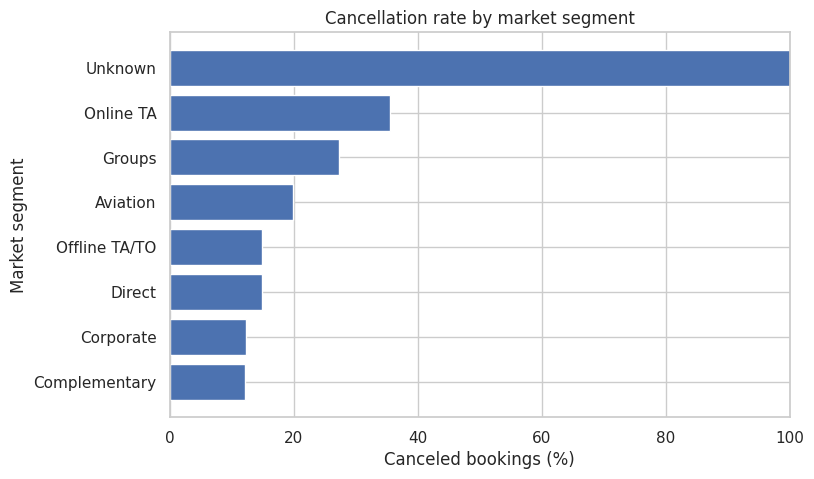

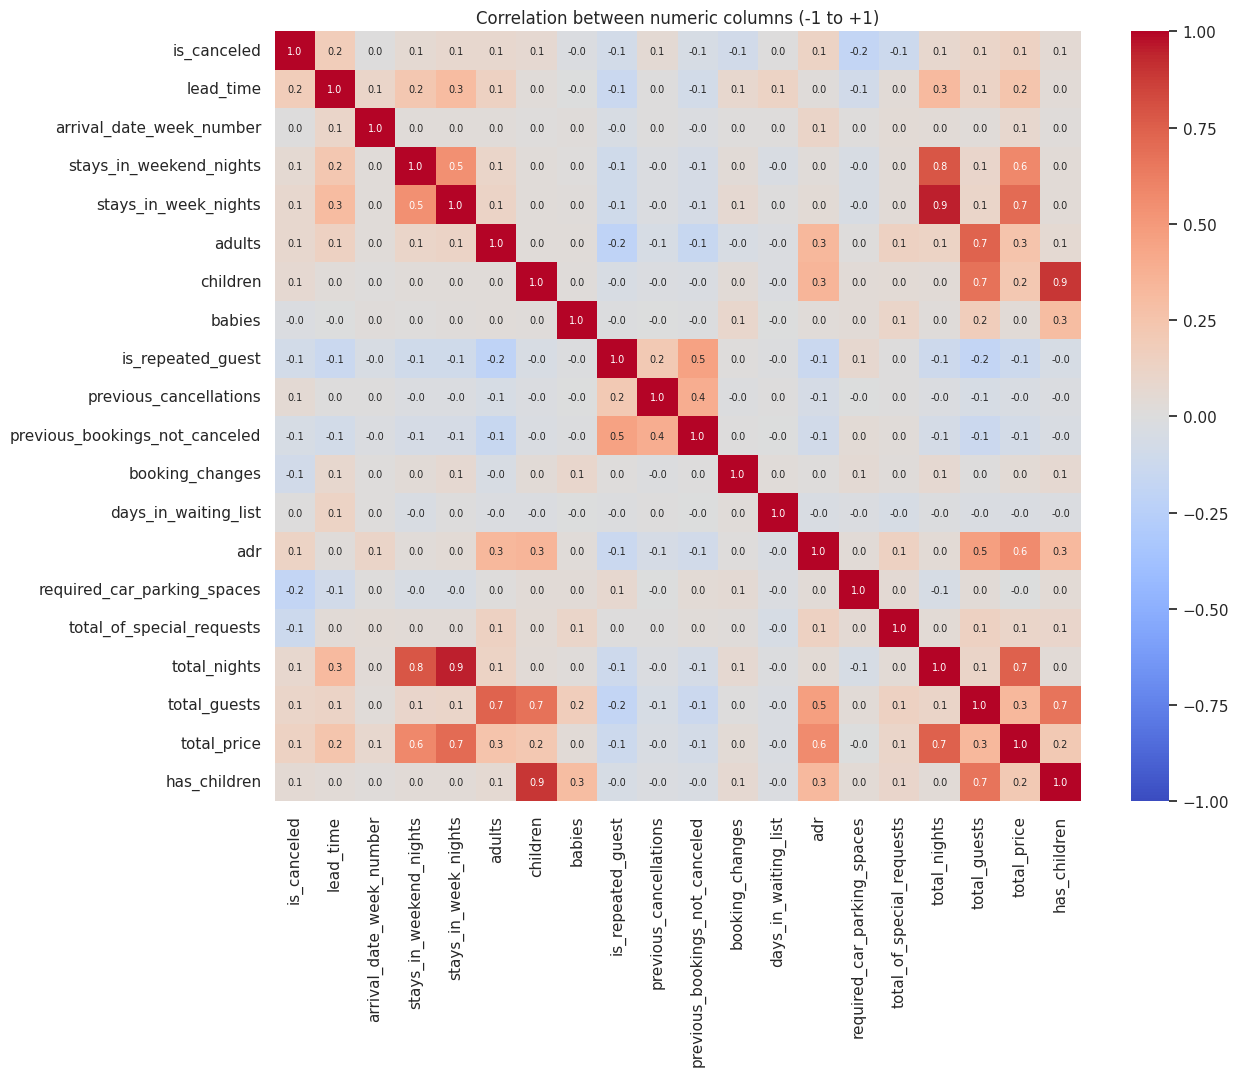

In [ ]:
#PART H: CHARTS
sns.set_theme(style="whitegrid")
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]

# Chart 1: How far ahead do people book? -> HISTOGRAM: one numeric column, shows the shape (right-skewed).
plt.figure(figsize=(9, 5))
sns.histplot(df.loc[df.lead_time <= 500, "lead_time"], bins=50)
plt.title("Lead time of bookings (bookings above 500 days not shown)")
plt.xlabel("Lead time (days between booking and arrival)"); plt.ylabel("Number of bookings")
plt.show()   # shows: most guests book within the last few weeks, a long tail books months ahead

# Chart 2: Which hotel has more cancellations? -> COUNT BAR (counts, starts at 0), split by status.
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="hotel", hue=TARGET)
plt.title("Bookings by hotel and cancellation status"); plt.xlabel("Hotel"); plt.ylabel("Number of bookings")
plt.legend(title="Canceled (1 = yes)"); plt.show()

# Chart 3: Price during the year per hotel -> LINE: ordered time (months), one line per hotel.
price = df.groupby(["hotel", df.arrival_date.dt.month_name()])["adr"].mean().unstack(0).reindex(month_order)
price.plot(marker="o", figsize=(10, 5))
plt.title("Average daily price by arrival month"); plt.xlabel("Arrival month"); plt.ylabel("Average daily rate (euro per night)")
plt.xticks(range(12), [m[:3] for m in month_order]); plt.show()

# Chart 4: Which segments cancel most? -> HORIZONTAL BAR of % (long labels, sorted, axis 0-100).
seg = (df.groupby("market_segment")[TARGET].mean() * 100).sort_values()
plt.figure(figsize=(8, 5)); plt.barh(seg.index, seg.values)
plt.xlim(0, 100); plt.title("Cancellation rate by market segment")
plt.xlabel("Canceled bookings (%)"); plt.ylabel("Market segment"); plt.show()

# Chart 5: Which numeric columns relate? -> HEATMAP of correlations (many pairs in one picture).
num = df.select_dtypes("number").drop(columns=["agent", "company"])   # IDs are not quantities
plt.figure(figsize=(13, 10))
sns.heatmap(num.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlation between numeric columns (-1 to +1)"); plt.show()
# shows: total_price/total_nights/stay columns move together; lead_time has the strongest link with is_canceled.

# PART I: REFLECTION
# 1) Hardest decision: probably duplicates or adr outliers. What changes if I decide the other way?
#    -> write both cancel rates / row counts and say how the manager's numbers would change.
# 2) Two things I still don't trust:
#    a) deposit_type 'Non Refund' with a very high cancel rate -> ask the hotel when deposit_type is recorded.
#    b) adr == 0 and duplicates -> ask the hotel if free stays and repeat bookings can be identified booking ID?.
# 3) Three sentences for the manager: what was cleaned and how many rows were removed; what the
#    cancel rate is with or without duplicates; what to fix before the model leaks removed, Non Refund question.